# 직전 1분 집계 모델 — IF · K-means · LOF

비교용 v7 릴리스입니다. **최신 원본 행 모델이 아닙니다.** 5개 시나리오 전체 결과와 최신 비교에 사용한 4개 시나리오의 4,600사례 부분집합을 혼동하지 않습니다.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'model_manifest.json').is_file())
read=lambda p: json.loads((ROOT/p).read_text(encoding='utf-8'))
plt.rcParams.update({'axes.spines.top':False,'axes.spines.right':False,'font.size':11})
NAMES={'if':'Isolation Forest','kmeans':'MiniBatch K-means','lof':'LOF'}
KEYS=['accuracy','precision','recall','f1']


## 1. 기존 전체 결과

5개 시나리오 전체 집계입니다. 수치는 %이며 최신 모델과 같은 부분집합의 비교는 다음 절에 따로 표시합니다.

,Model,accuracy,precision,recall,f1,FPR
0,Isolation Forest,94.01,90.33,73.00,80.74,1.63
1,MiniBatch K-means,93.66,92.93,68.38,78.79,1.08
2,LOF,93.81,89.60,72.44,80.11,1.75


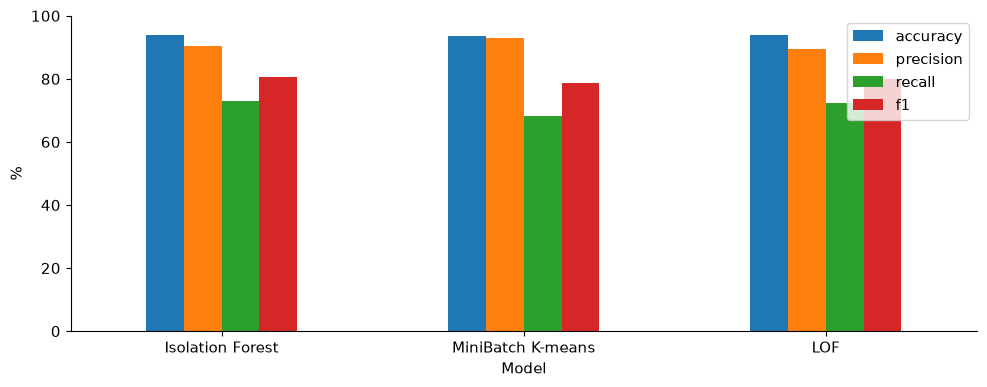

In [2]:
summary=read('results/previous_minute/summary.json')
table=pd.DataFrame([{'Model':NAMES[r['method']], **{k:100*r[k] for k in KEYS}, 'FPR':100*r['normal_false_positive_rate']} for r in summary['pooled']])
display(table.round(2))
table.set_index('Model')[KEYS].plot.bar(figsize=(10,4),rot=0,ylim=(0,100));plt.ylabel('%');plt.tight_layout();plt.show()


## 2. 입력과 한계

입력은 연속 1분 감시 격자와 완료 Process 관측입니다. 빈 분을 공급하고 과거 이력을 유지하는 worker는 별도 구현입니다. 소요시간·빈도·공백 통계 및 개발 정답 기반 보정을 포함하며 순수 알고리즘 단독 성능이 아닙니다.

## 동일한 기준의 직전·최신 비교

같은 4개 시나리오·확인 사례·분 정답으로 계산한 F1입니다. 학습 입력은 달라도 비교 지표의 단위는 같습니다.

,Task,Model,Previous F1,Latest F1,Change (pp)
0,individual_delay,Isolation Forest,87.51,89.88,2.37
1,individual_delay,MiniBatch K-means,80.01,84.90,4.90
2,individual_delay,LOF,83.05,85.08,2.03
3,group_delay,Isolation Forest,89.71,93.51,3.80
4,group_delay,MiniBatch K-means,92.90,93.17,0.28
5,group_delay,LOF,89.54,89.82,0.28
6,time_burst,Isolation Forest,66.78,67.38,0.60
7,time_burst,MiniBatch K-means,67.74,67.43,-0.32
8,time_burst,LOF,67.02,65.67,-1.34
9,gradual_degradation,Isolation Forest,78.03,81.35,3.32


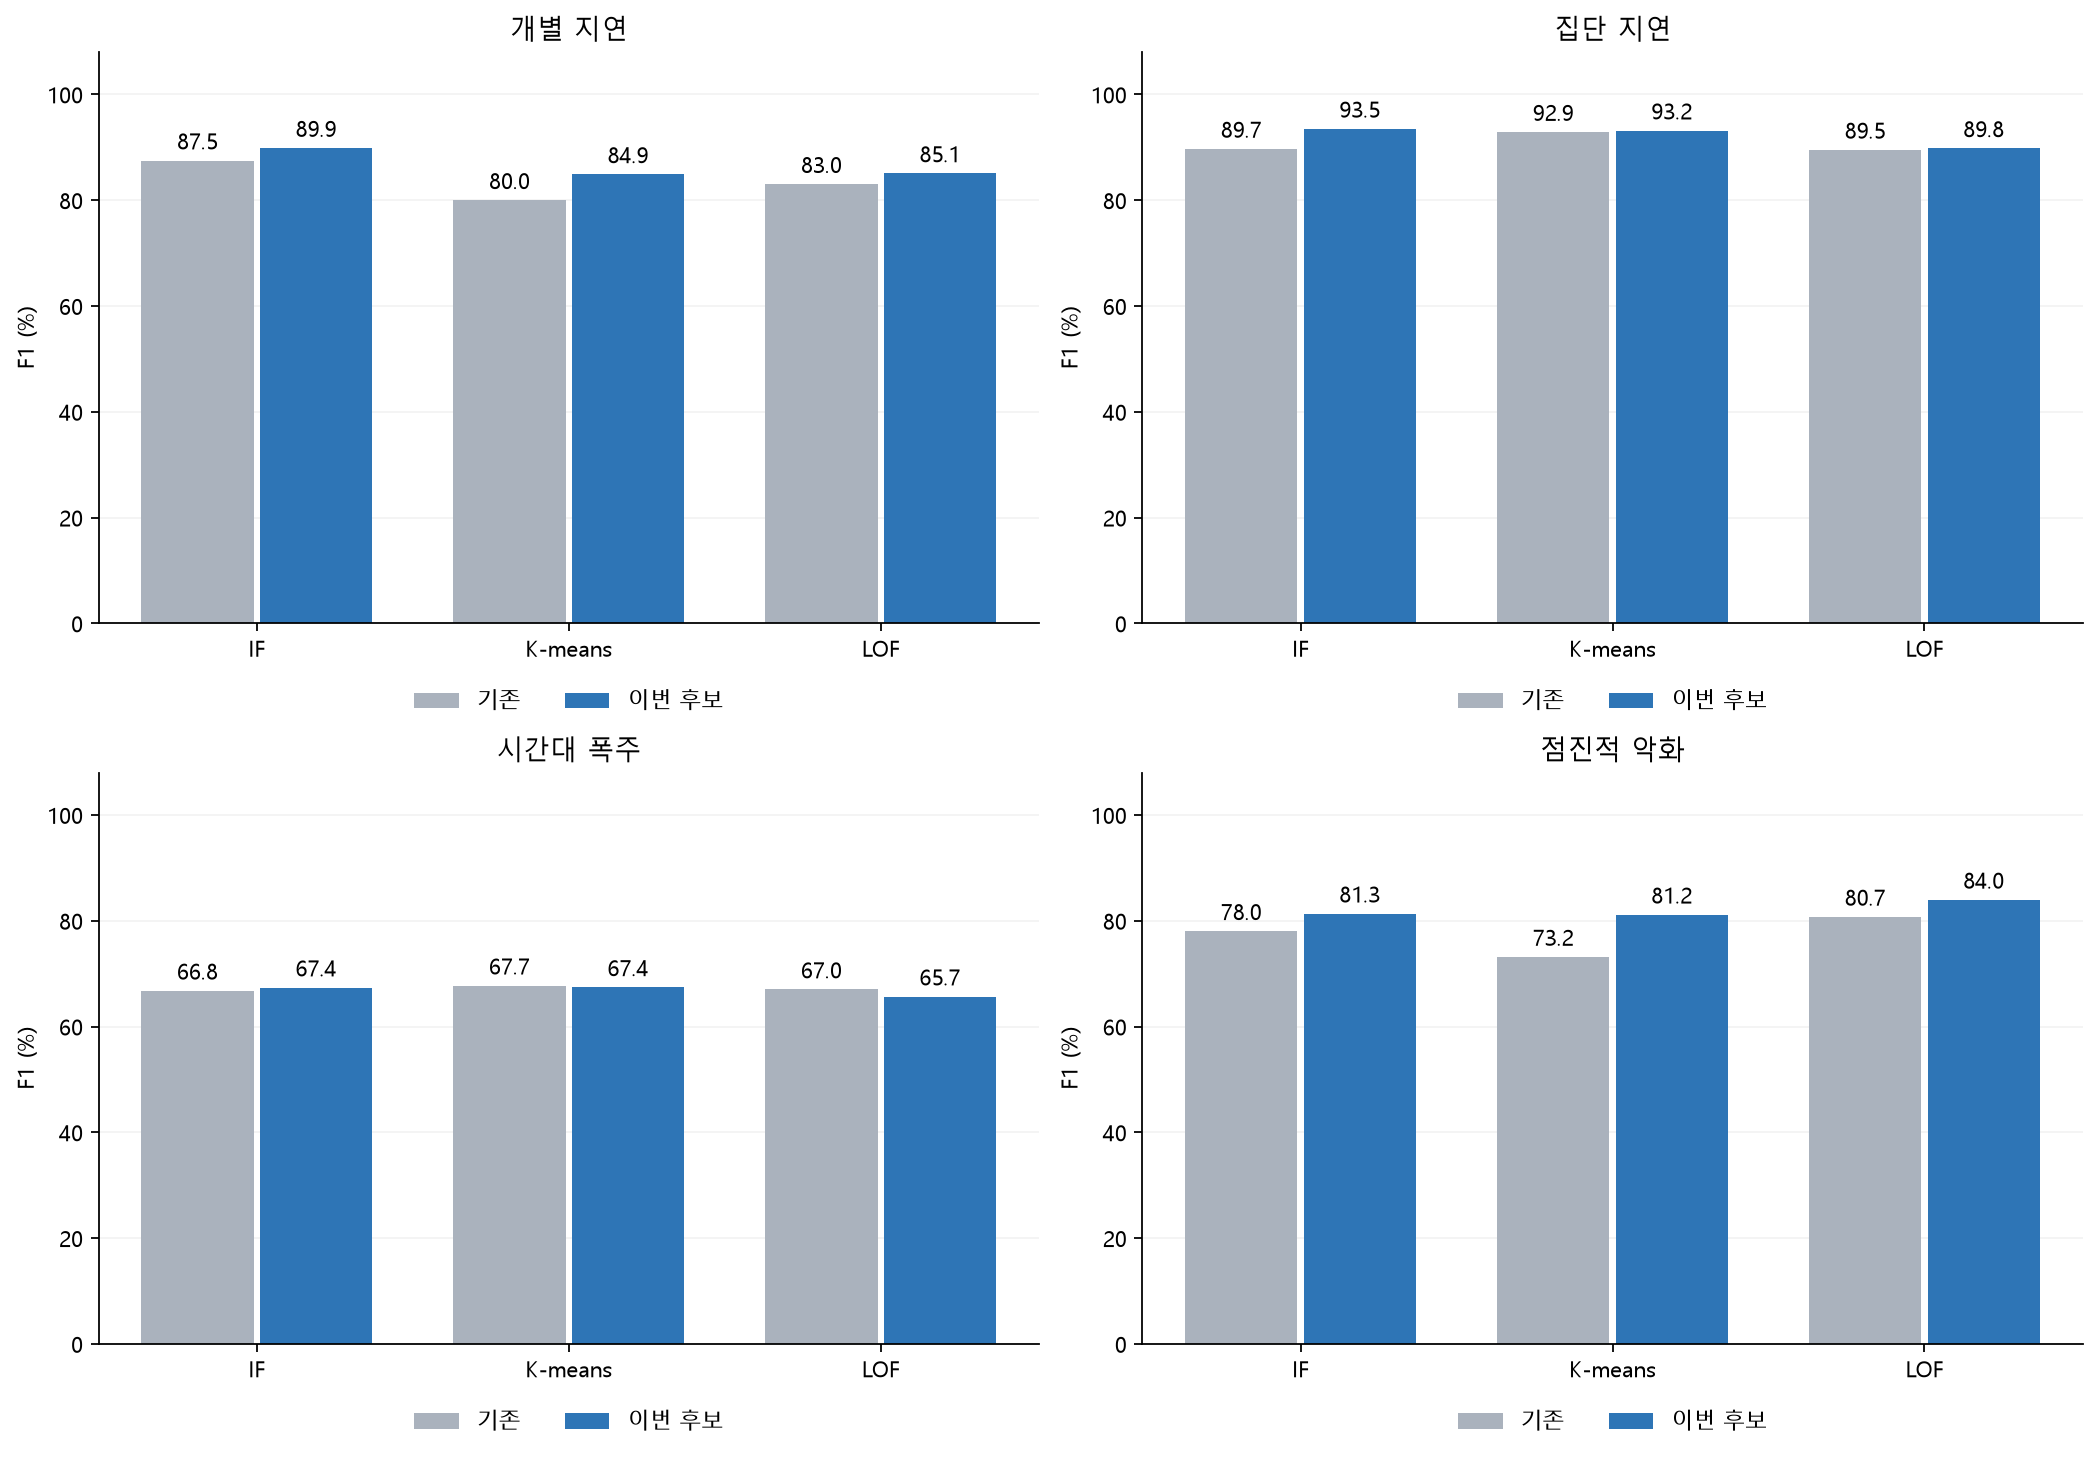

In [3]:
r=read('results/latest/minute_confirmation.json')
comparison=pd.DataFrame([{'Task':t,'Model':NAMES[a],'Previous F1':100*d['legacy'][a]['f1'],'Latest F1':100*d['current'][a]['f1'],'Change (pp)':d['delta_percentage_points'][a]['f1']} for t,d in r['tasks'].items() for a in NAMES])
display(comparison.round(2))
display(Image(filename=str(ROOT/'results/latest/same_minute_f1_comparison.png')))


## 학습・再現上の注意

원본 정상 후보로 sklearn 추정기를 학습했고, 최신의 추가 요일·시간대 건수 참조에는 기존 합성 개발 정상 대조군을 사용했습니다. 설정·경보 기준 선택에 개발 정답을 사용했습니다. 정상-only 재학습 baseline은 이 보정 전체나 공개 성능을 상속하지 않습니다. 자세한 입력·실행·제약은 README.md, REPRODUCING.md, MODEL_COMPARISON.md를 확인하십시오.

이 노트북은 포함된 집계 결과만 읽습니다. 원본 CSV·벤치마크·개발 캐시 없이 실행되지만 모델을 재평가하는 것은 아닙니다.